Total features after one-hot encoding: 117

Chi-Squared Selected Features Accuracy: 97.58%
Top Chi-Squared features (indices): [21, 24, 27, 36, 37, 57, 61, 92, 94, 96]

Mutual Information Selected Features Accuracy: 97.58%
Top Mutual Information features (indices): [20, 24, 27, 35, 36, 37, 57, 61, 94, 96]


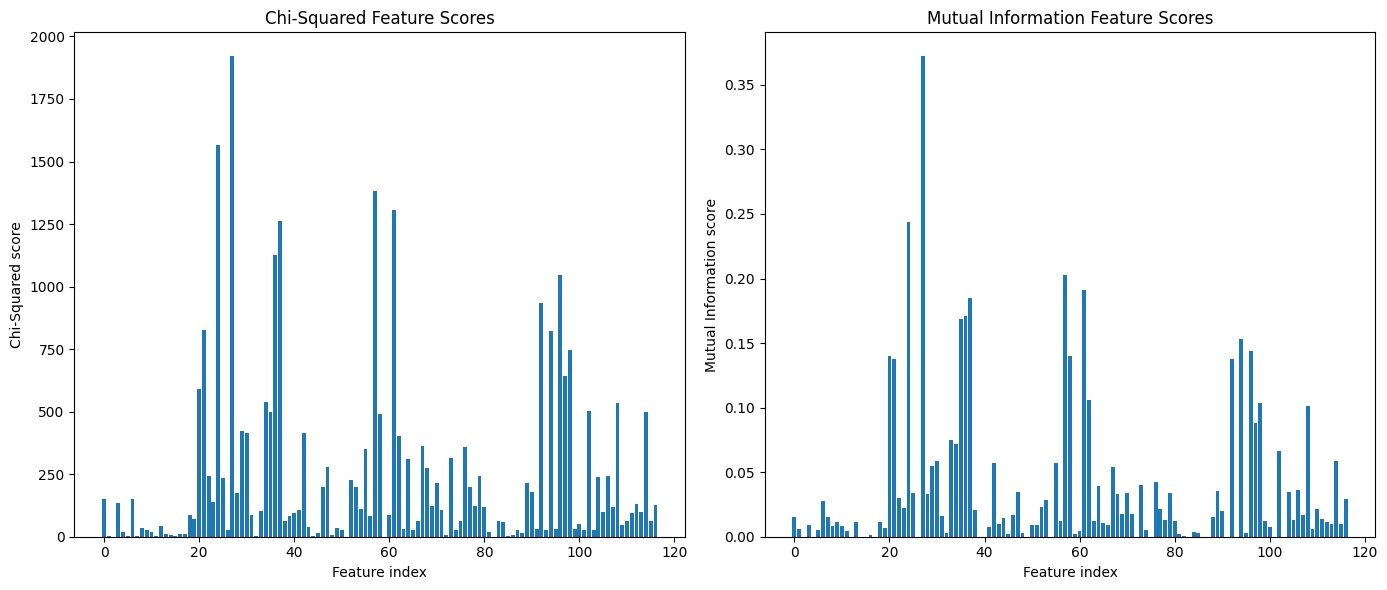


Top Chi-Squared Features:
                            Feature   Chi2 Score
27                      cat__odor_n  1920.485806
24                      cat__odor_f  1566.084960
57  cat__stalk-surface-above-ring_k  1380.807527
61  cat__stalk-surface-below-ring_k  1306.630206
37                cat__gill-color_b  1263.915040
36                 cat__gill-size_n  1124.382043
96         cat__spore-print-color_h  1045.571404
92                 cat__ring-type_l   933.585917
21                   cat__bruises_t   825.153563
94                 cat__ring-type_p   821.472306

Top Mutual Information Features:
                            Feature  Mutual Information Score
27                      cat__odor_n                  0.372075
24                      cat__odor_f                  0.243983
57  cat__stalk-surface-above-ring_k                  0.202739
61  cat__stalk-surface-below-ring_k                  0.191454
37                cat__gill-color_b                  0.184933
36                 cat__gill

In [11]:
# -------------------------
# Mushroom Dataset: Chi-Squared vs Mutual Information
# -------------------------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from ucimlrepo import fetch_ucirepo

# -------------------------
# Fetch Mushroom dataset
# -------------------------
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features
y = mushroom.data.targets

# Convert target to 1D array
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

# Encode target if categorical
if y.dtype == object:
    y = LabelEncoder().fit_transform(y)

# Detect categorical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# One-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'
)
X_encoded = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
print(f"Total features after one-hot encoding: {X_encoded.shape[1]}")

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.33, random_state=42
)

# -------------------------
# Chi-Squared Feature Selection
# -------------------------
k = min(10, X_train.shape[1])
fs_chi2 = SelectKBest(score_func=chi2, k=k)
fs_chi2.fit(X_train, y_train)
X_train_chi2 = fs_chi2.transform(X_train)
X_test_chi2 = fs_chi2.transform(X_test)
chi2_indices = fs_chi2.get_support(indices=True)
chi2_scores = fs_chi2.scores_

# Train Logistic Regression on Chi-Squared features
model_chi2 = LogisticRegression(solver='lbfgs', max_iter=5000)
model_chi2.fit(X_train_chi2, y_train)
yhat_chi2 = model_chi2.predict(X_test_chi2)
acc_chi2 = accuracy_score(y_test, yhat_chi2)
print(f"\nChi-Squared Selected Features Accuracy: {acc_chi2*100:.2f}%")
print(f"Top Chi-Squared features (indices): {chi2_indices.tolist()}")

# -------------------------
# Mutual Information Feature Selection
# -------------------------
fs_mi = SelectKBest(score_func=mutual_info_classif, k=k)
fs_mi.fit(X_train, y_train)
X_train_mi = fs_mi.transform(X_train)
X_test_mi = fs_mi.transform(X_test)
mi_indices = fs_mi.get_support(indices=True)
mi_scores = fs_mi.scores_

# Train Logistic Regression on Mutual Information features
model_mi = LogisticRegression(solver='lbfgs', max_iter=5000)
model_mi.fit(X_train_mi, y_train)
yhat_mi = model_mi.predict(X_test_mi)
acc_mi = accuracy_score(y_test, yhat_mi)
print(f"\nMutual Information Selected Features Accuracy: {acc_mi*100:.2f}%")
print(f"Top Mutual Information features (indices): {mi_indices.tolist()}")

# -------------------------
# Plot feature scores
# -------------------------
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.bar(range(len(chi2_scores)), chi2_scores)
plt.xlabel("Feature index")
plt.ylabel("Chi-Squared score")
plt.title("Chi-Squared Feature Scores")

plt.subplot(1,2,2)
plt.bar(range(len(mi_scores)), mi_scores)
plt.xlabel("Feature index")
plt.ylabel("Mutual Information score")
plt.title("Mutual Information Feature Scores")

plt.tight_layout()
plt.show()

# -------------------------
# Optional: Display top features with scores
# -------------------------
chi2_df = pd.DataFrame({
    "Feature": feature_names,
    "Chi2 Score": chi2_scores
}).sort_values(by="Chi2 Score", ascending=False)
print("\nTop Chi-Squared Features:")
print(chi2_df.head(10))

mi_df = pd.DataFrame({
    "Feature": feature_names,
    "Mutual Information Score": mi_scores
}).sort_values(by="Mutual Information Score", ascending=False)
print("\nTop Mutual Information Features:")
print(mi_df.head(10))
